# 1D → 2D Lagrange interpolation using uniformly spaced boundary-inclusive nodes
### Tensor products on a rectangular reference element · Q1, Q2, Q3

## Lagrange interpolation in one dimension

For polynomial degree $p$, choose $p+1$ **uniformly spaced nodes including the endpoints** $s_0,\ldots,s_p$ on $[-1,1]$. The $i$th Lagrange basis polynomial is

$$
\boxed{\ell_i^{(p)}(s)=\prod_{\substack{k=0\\ k\neq i}}^p\frac{s-s_k}{s_i-s_k}}.
$$

Each $\ell_i$ has degree $p$ and obeys

$$\ell_i(s_j)=\delta_{ij},\qquad \sum_{i=0}^{p}\ell_i(s)=1.$$

The **interpolation points**, not the formula itself, specify the particular Lagrange basis.

| Degree $p$ | Number of points | Uniform coordinates |
|---|---:|---|
| 1 (linear) | 2 | $-1,\ 1$ |
| 2 (quadratic) | 3 | $-1,\ 0,\ 1$ |
| 3 (cubic) | 4 | $-1,\ -\tfrac13,\ \tfrac13,\ 1$ |

The code uses `np.linspace(-1, 1, p+1)` to include the element endpoints.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def uniform_nodes(p):
    """p+1 ordered uniformly spaced interpolation nodes on [-1,1], including endpoints."""
    return np.linspace(-1.0, 1.0, p + 1)


def lagrange_1d(s, nodes):
    """Evaluate every cardinal Lagrange polynomial at s.

    Return shape: (number_of_nodes, *np.shape(s)).
    """
    s = np.asarray(s, dtype=float)
    L = np.ones((len(nodes),) + s.shape, dtype=float)
    for i in range(len(nodes)):
        for k in range(len(nodes)):
            if k != i:
                L[i] *= (s - nodes[k]) / (nodes[i] - nodes[k])
    return L


for p in (1, 2, 3):
    print(f'p={p}, {p+1} uniform nodes: {np.round(uniform_nodes(p), 8)}')

p=1, 2 uniform nodes: [-1.  1.]
p=2, 3 uniform nodes: [-1.  0.  1.]
p=3, 4 uniform nodes: [-1.         -0.33333333  0.33333333  1.        ]


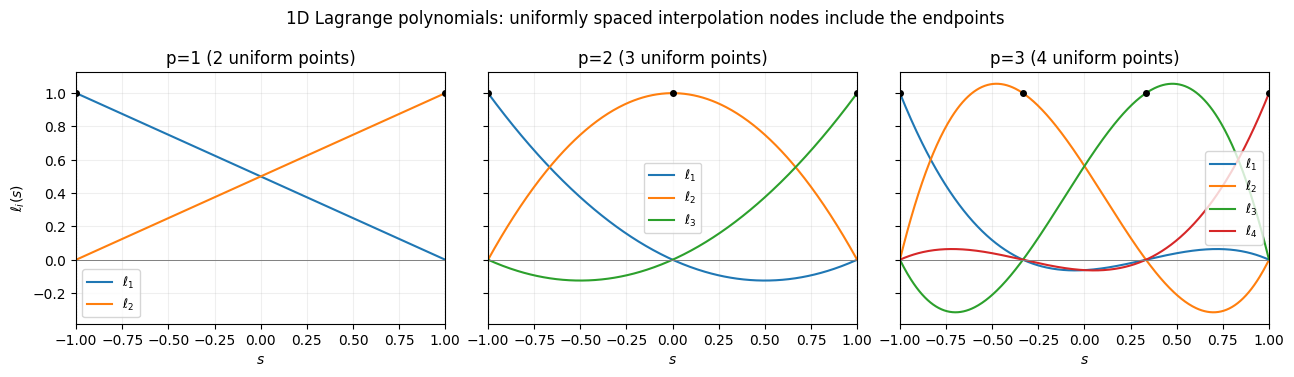

In [ ]:
# 1D basis functions for each polynomial degree
s = np.linspace(-1, 1, 401)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, p in zip(axes, (1, 2, 3)):
    nodes = uniform_nodes(p)
    basis = lagrange_1d(s, nodes)
    for i in range(p + 1):
        ax.plot(s, basis[i], label=rf'$\ell_{{{i+1}}}$')
        ax.plot(nodes[i], 1.0, 'ko', ms=4)
    ax.axhline(0, color='0.5', linewidth=0.7)
    ax.axvline(-1, color='0.4', linestyle=':', linewidth=0.8)
    ax.axvline(+1, color='0.4', linestyle=':', linewidth=0.8)
    ax.grid(alpha=0.2)
    ax.set(xlim=(-1, 1), xlabel='$s$', title=f'p={p} ({p+1} uniform points)')
    ax.legend(fontsize=9)
axes[0].set_ylabel(r'$\ell_i(s)$')
fig.suptitle('1D Lagrange polynomials: uniformly spaced interpolation nodes include the endpoints')
plt.tight_layout()
plt.show()

### 1D Lagrange shape functions: quadratic 3-node element

Take the uniformly spaced natural-coordinate points $s_1=-1$, $s_2=0$, and $s_3=1$. The three **quadratic Lagrange functions** are

$$
\boxed{N_1(s)=\frac{s(s-1)}{2},\qquad
       N_2(s)=1-s^2,\qquad
       N_3(s)=\frac{s(s+1)}{2}.}
$$

For comparison, the **2-node linear element** has $N_1(s)=(1-s)/2$ and $N_2(s)=(1+s)/2$. The **4-node cubic element** has four corresponding third-degree Lagrange functions, constructed with the same general formula.


## From 1D to 2D by a tensor product

Let the rectangular **parent element** be

$$\widehat\Omega=[-1,1]\times[-1,1].$$

Take **one** 1D Lagrange function along $\xi$ and **one** along $\eta$:

$$\boxed{N_{ij}(\xi,\eta)=\ell_i^{(p)}(\xi)\ell_j^{(p)}(\eta)}.$$

The $(p+1)$ nodes along each axis produce a Cartesian-product grid:

$$\boxed{n=(p+1)(p+1)=(p+1)^2}.$$

The interpolated field is

$$\boxed{u^h(\xi,\eta)=\sum_{j=0}^p\sum_{i=0}^p
u_{ij}\,\ell_i^{(p)}(\xi)\ell_j^{(p)}(\eta)}.$$

This is **tensor-product interpolation**. We number the points row-by-row, from lower $\eta$ to higher $\eta$, and from left $\xi$ to right $\xi$ within each row. **Uniform nodes include the boundary corners and edges**; higher-order elements also contain interior nodes.

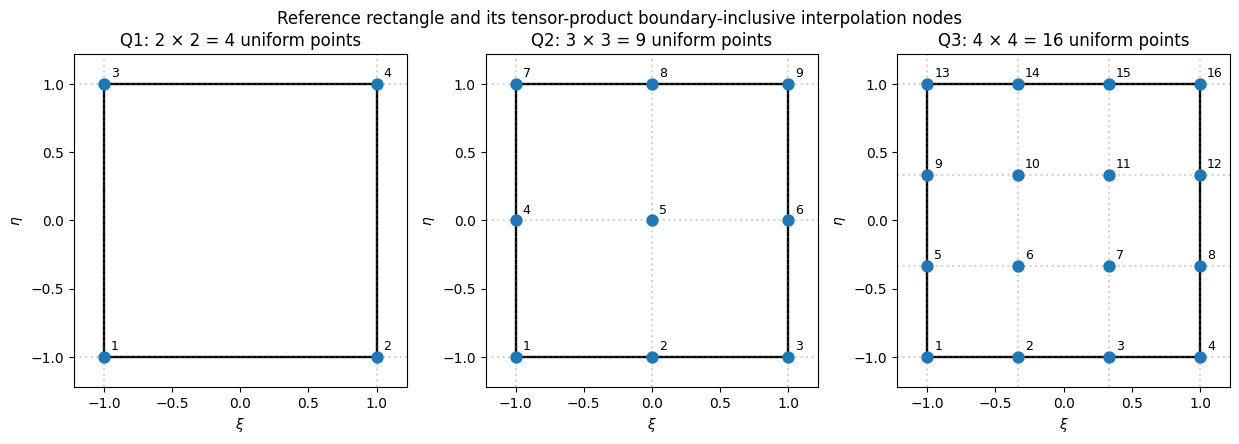

In [ ]:
def node_pairs(p):
    """(i,j) in row-major order: j outer, i inner."""
    return [(i, j) for j in range(p + 1) for i in range(p + 1)]


def uniform_2d_nodes(p):
    """Return two 1D-coordinate arrays, both of length (p+1)^2."""
    nodes = uniform_nodes(p)
    pairs = node_pairs(p)
    return (np.array([nodes[i] for i, j in pairs]),
            np.array([nodes[j] for i, j in pairs]))


def tensor_basis(p, xi, eta):
    """All 2D tensor-product Lagrange functions on uniformly spaced nodes.

    xi, eta may be scalars or identically shaped arrays.
    First index selects the shape function.
    """
    r = uniform_nodes(p)
    Lxi = lagrange_1d(xi, r)
    Leta = lagrange_1d(eta, r)
    return np.array([Lxi[i] * Leta[j] for i, j in node_pairs(p)])


fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3))
for ax, p in zip(axes, (1, 2, 3)):
    xi_nodes, eta_nodes = uniform_2d_nodes(p)
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], 'k-', lw=1.7)
    for r in uniform_nodes(p):
        ax.axvline(r, linestyle=':', alpha=0.3, color='0.45')
        ax.axhline(r, linestyle=':', alpha=0.3, color='0.45')
    ax.scatter(xi_nodes, eta_nodes, s=62, zorder=3)
    for a, (x, y) in enumerate(zip(xi_nodes, eta_nodes), 1):
        ax.annotate(str(a), (x, y), xytext=(5, 5), textcoords='offset points', fontsize=9)
    ax.set(aspect='equal', xlim=(-1.22, 1.22), ylim=(-1.22, 1.22),
           xlabel=r'$\xi$', ylabel=r'$\eta$',
           title=f'Q{p}: {p+1} × {p+1} = {(p+1)**2} uniform points')
fig.suptitle('Reference rectangle and its tensor-product boundary-inclusive interpolation nodes')
plt.tight_layout()
plt.show()

## What do the two-dimensional shape functions look like?

Each plot below represents **one** tensor-product basis function. For $p=1$, with uniform nodes $-1$ and $+1$, the lower-left basis is

$$
N_{00}(\xi,\eta)=\frac14(1-\xi)(1-\eta).
$$

For $p=2$, the **middle node** is $(0,0)$, so its basis is

$$
N_{11}(\xi,\eta)=(1-\xi^2)(1-\eta^2).
$$


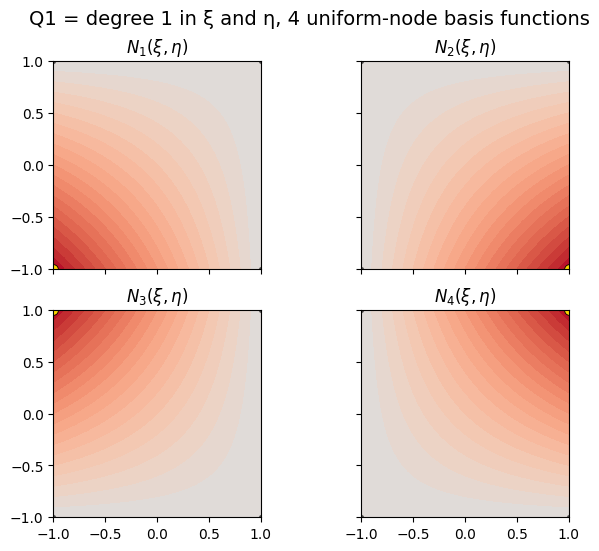

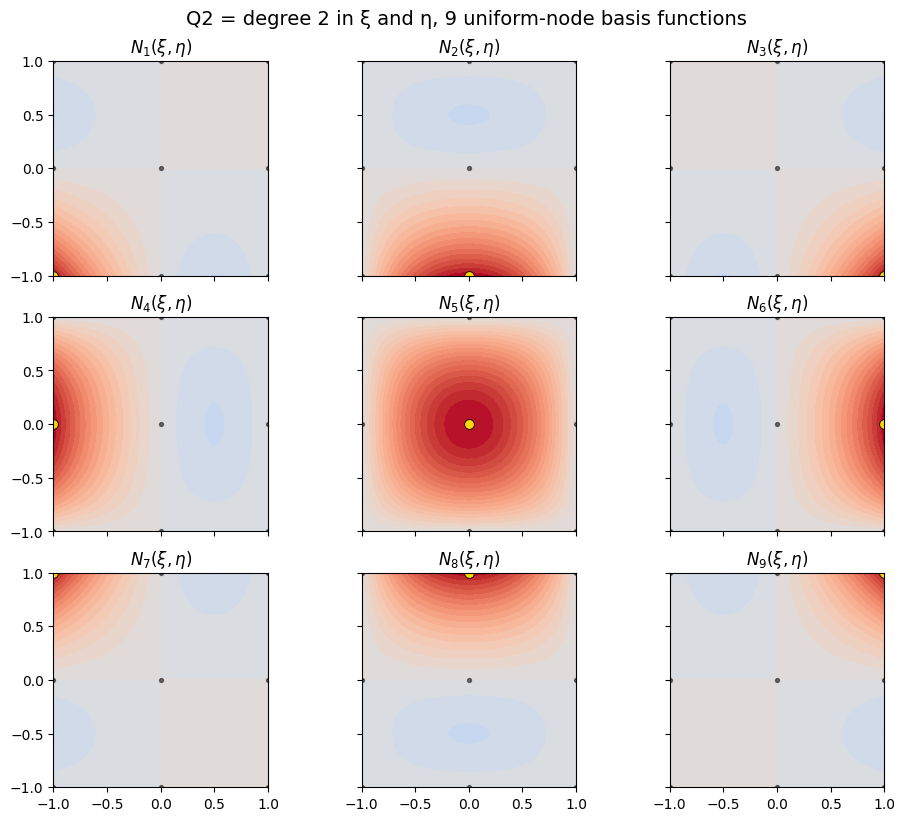

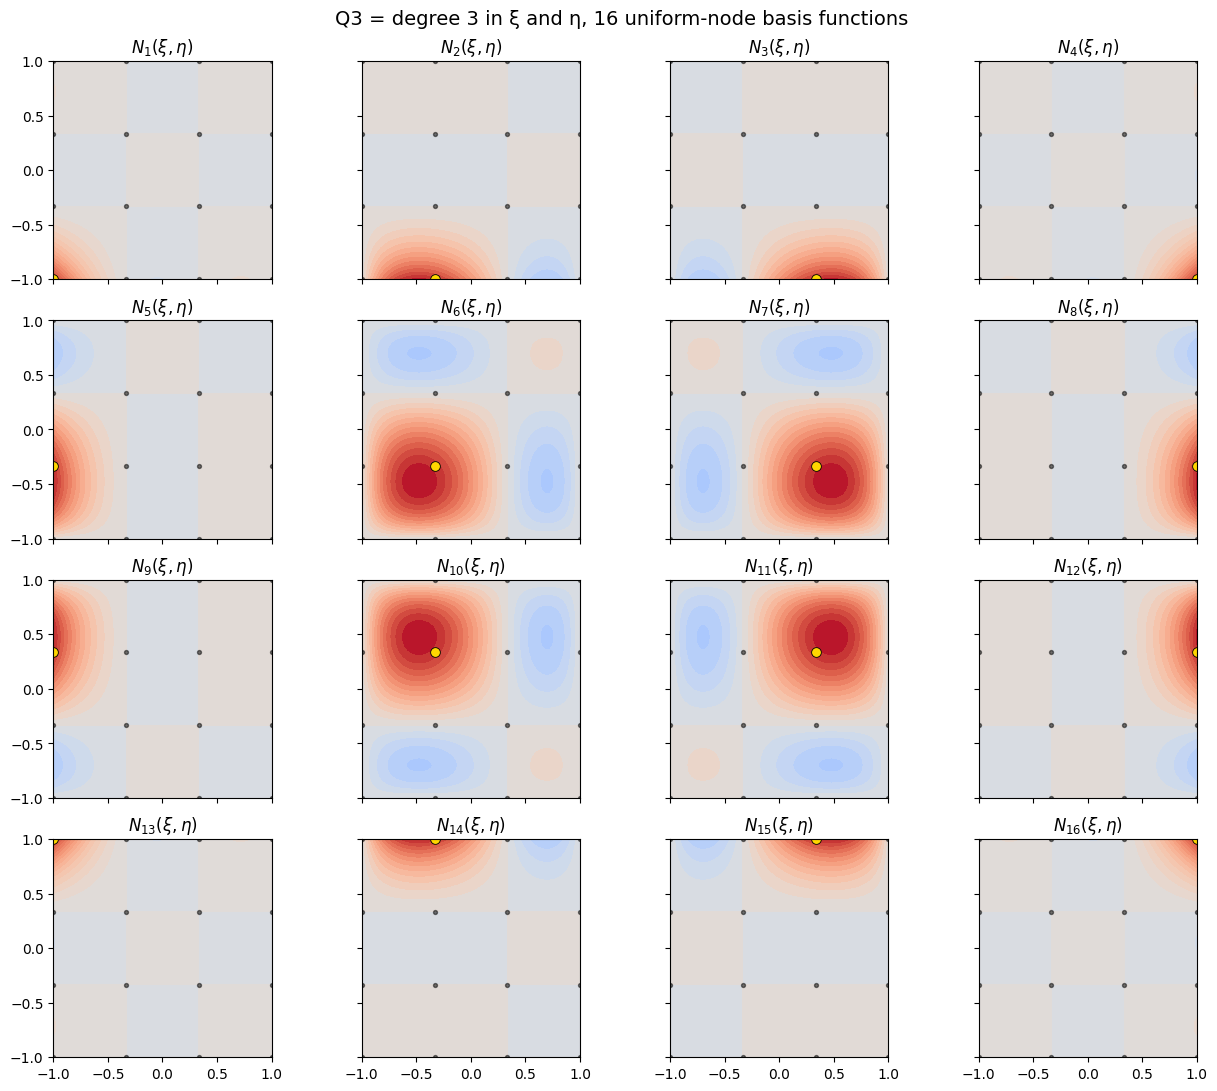

In [ ]:
def plot_2d_shape_functions(p):
    r = np.linspace(-1.0, 1.0, 81)
    XI, ETA = np.meshgrid(r, r)
    N = tensor_basis(p, XI, ETA)
    nodex, nodey = uniform_2d_nodes(p)
    side = p + 1
    fig, axes = plt.subplots(side, side, figsize=(3.1 * side, 2.7 * side),
                             constrained_layout=True)
    scale = np.max(np.abs(N))
    for a, ax in enumerate(np.asarray(axes).flat):
        ax.contourf(XI, ETA, N[a], levels=19, vmin=-scale, vmax=scale, cmap='coolwarm')
        ax.plot([-1,1,1,-1,-1], [-1,-1,1,1,-1], 'k-', lw=0.6)
        ax.scatter(nodex, nodey, color='k', s=8, alpha=0.5)
        ax.plot(nodex[a], nodey[a], 'o', color='gold', mec='black', mew=0.6, ms=7)
        ax.set(aspect='equal', xlim=(-1,1), ylim=(-1,1), title=rf'$N_{{{a+1}}}(\xi,\eta)$')
        if a // side < side-1:
            ax.set_xticklabels([])
        if a % side:
            ax.set_yticklabels([])
    fig.suptitle(f'Q{p} = degree {p} in ξ and η, {(p+1)**2} uniform-node basis functions', fontsize=14)
    plt.show()

for p in (1, 2, 3):
    plot_2d_shape_functions(p)

## Coordinate transformation: natural rectangle $\boldsymbol{(\xi,\eta)}$ to physical rectangle $\boldsymbol{(x,y)}$

The **natural (parent) rectangle** is $-1\leq\xi,\eta\leq1$. Suppose the **physical rectangle** extends from $x=x_a$ to $x=x_b$ and from $y=y_a$ to $y=y_b$.

Start with the familiar **1D linear mapping** for each direction:

$$
\boxed{x(\xi)=\frac{1-\xi}{2}\,x_a+\frac{1+\xi}{2}\,x_b},
\qquad
\boxed{y(\eta)=\frac{1-\eta}{2}\,y_a+\frac{1+\eta}{2}\,y_b}.
$$

This sends $\xi=-1$ to $x_a$, $\xi=1$ to $x_b$, $\eta=-1$ to $y_a$, and $\eta=1$ to $y_b$. The natural center $(0,0)$ maps to the physical center.

For the 2D tensor-product Lagrange functions already constructed, the **same mapping** can also be written as coordinate interpolation:

$$
\boxed{x(\xi,\eta)=\sum_{a=1}^{(p+1)^2}N_a(\xi,\eta)x_a,\qquad
       y(\xi,\eta)=\sum_{a=1}^{(p+1)^2}N_a(\xi,\eta)y_a},
$$

where $(x_a,y_a)$ are the physical coordinates of the **same** $Q_p$ interpolation nodes. On a rectangle, this reduces exactly to the two simple linear expressions above, for $p=1,2,$ or $3$.

The inverse mapping and Jacobian are especially simple:

$$
\boxed{\xi=\frac{2(x-x_a)}{x_b-x_a}-1,\qquad
\eta=\frac{2(y-y_a)}{y_b-y_a}-1},
\qquad
\boxed{\mathbf J=\begin{bmatrix}\dfrac{x_b-x_a}{2}&0\\0&\dfrac{y_b-y_a}{2}\end{bmatrix}}.
$$

The example below displays the **same Q2 node grid** in natural and physical coordinates, and maps one interior sample point.

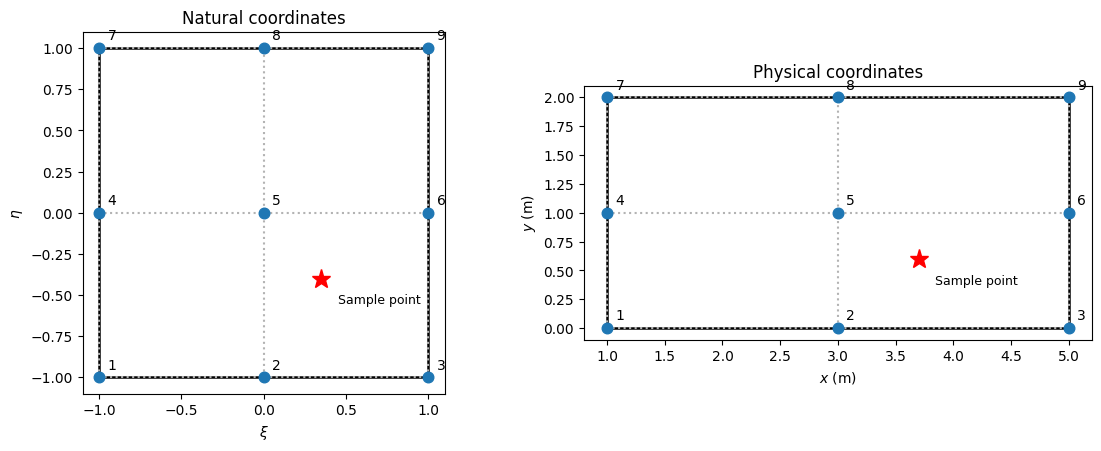

Natural point (xi, eta) = (0.35, -0.40)
Physical point (x, y)   = (3.70, 0.60) m
Back to natural (xi, eta): (0.3500000000000001, -0.4)
Q1 max coordinate mapping error: 8.88e-16 m
Q2 max coordinate mapping error: 1.78e-15 m
Q3 max coordinate mapping error: 2.66e-15 m


In [ ]:
# Coordinate mapping of a RECTANGULAR element
xa, xb = 1.0, 5.0  # physical x coordinates (m)
ya, yb = 0.0, 2.0  # physical y coordinates (m)
p = 2             # Q2 example: 3 x 3 uniformly spaced nodes

# The natural coordinates of all nine Q2 nodes
xi_nodes, eta_nodes = uniform_2d_nodes(p)

# Direct affine map from natural to physical coordinates
def natural_to_physical(xi, eta):
    x = 0.5 * (1 - xi) * xa + 0.5 * (1 + xi) * xb
    y = 0.5 * (1 - eta) * ya + 0.5 * (1 + eta) * yb
    return x, y


def physical_to_natural(x, y):
    xi = 2 * (x - xa) / (xb - xa) - 1
    eta = 2 * (y - ya) / (yb - ya) - 1
    return xi, eta

x_nodes, y_nodes = natural_to_physical(xi_nodes, eta_nodes)

# one interior location in the parent and physical rectangles
xi_sample, eta_sample = 0.35, -0.40
x_sample, y_sample = natural_to_physical(xi_sample, eta_sample)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, xx, yy, xmin, xmax, ymin, ymax, xstar, ystar, xlabel, ylabel, title in [
    (axes[0], xi_nodes, eta_nodes, -1, 1, -1, 1, xi_sample, eta_sample,
     r'$\xi$', r'$\eta$', 'Natural coordinates'),
    (axes[1], x_nodes, y_nodes, xa, xb, ya, yb, x_sample, y_sample,
     '$x$ (m)', '$y$ (m)', 'Physical coordinates'),
]:
    ax.plot([xmin, xmax, xmax, xmin, xmin],
            [ymin, ymin, ymax, ymax, ymin], 'k-', lw=1.8)
    for fixed in uniform_nodes(p):
        mapped_x = xmin + 0.5 * (fixed + 1) * (xmax - xmin)
        mapped_y = ymin + 0.5 * (fixed + 1) * (ymax - ymin)
        ax.plot([mapped_x, mapped_x], [ymin, ymax], ':', color='0.7')
        ax.plot([xmin, xmax], [mapped_y, mapped_y], ':', color='0.7')
    ax.scatter(xx, yy, s=58, zorder=3)
    for k, (xval, yval) in enumerate(zip(xx, yy), 1):
        ax.annotate(str(k), (xval, yval), xytext=(6, 6), textcoords='offset points')
    ax.plot(xstar, ystar, 'r*', ms=14, zorder=5)
    ax.annotate('Sample point', (xstar, ystar), xytext=(12, -18),
                textcoords='offset points', fontsize=9)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title, aspect='equal')
plt.show()

print(f'Natural point (xi, eta) = ({xi_sample:.2f}, {eta_sample:.2f})')
print(f'Physical point (x, y)   = ({x_sample:.2f}, {y_sample:.2f}) m')
print('Back to natural (xi, eta):', physical_to_natural(x_sample, y_sample))

# Verify coordinate mapping through the SAME Q2 tensor-product shape functions.
# This also works with Q1 or Q3 rectangular element nodes.
XI, ETA = np.meshgrid(np.linspace(-1, 1, 31), np.linspace(-1, 1, 31))
for p_check in (1, 2, 3):
    xi_a, eta_a = uniform_2d_nodes(p_check)
    x_a, y_a = natural_to_physical(xi_a, eta_a)
    N = tensor_basis(p_check, XI, ETA)
    x_by_shapes = np.tensordot(x_a, N, axes=(0, 0))
    y_by_shapes = np.tensordot(y_a, N, axes=(0, 0))
    x_direct, y_direct = natural_to_physical(XI, ETA)
    print(f'Q{p_check} max coordinate mapping error: '
          f'{max(np.max(np.abs(x_by_shapes-x_direct)), np.max(np.abs(y_by_shapes-y_direct))):.2e} m')